# 🔥 FIREWISE-X: Flame in Freefall
### AI-Powered Microgravity Fire Intelligence & Astronaut Safety Platform
**Built on NASA PSI-25 (BASS-II) Microgravity Combustion Flight Experiments**  
*Understand the Flame. Anticipate the Risk. Protect the Mission.*

> **RESEARCH PROTOTYPE NOTICE:** FIREWISE-X is a scientific decision-support system built for researchers, mission planners, and spacecraft safety engineers. It does not replace NASA-approved flight safety procedures or certified emergency suppression systems.

## 1. NASA PSI-25 Dataset Ingestion & Overview
Load the harmonized experimental database comprising **129 flight tests** conducted aboard the International Space Station (ISS) Microgravity Science Glovebox (MSG).

In [6]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure backend modules are in path
backend_dir = os.path.abspath('backend')
if backend_dir not in sys.path:
    sys.path.append(backend_dir)

data_path = os.path.join(backend_dir, 'data', 'experiments_clean.csv')
df = pd.read_csv(data_path)
print(f"Loaded {len(df)} NASA PSI-25 experiments.")
print("Principal Investigators:", df['pi'].value_counts().to_dict())
print("Combustion Outcomes:", df['outcome'].value_counts().to_dict())
df[['test_id', 'pi', 'material_category', 'calibrated_initial_o2_vol_pct', 'airflow_velocity_cm_s', 'outcome']].head(10)

Loaded 129 NASA PSI-25 experiments.
Principal Investigators: {"T'ien": 29, 'Olson': 27, 'Fernandez-Pello': 27, 'Bhattacharjee': 22, 'Miller': 20, 'Ferkul': 4}
Combustion Outcomes: {'extinguished_quenched': 69, 'sustained': 42, 'extinguished_blowoff': 10, 'no_ignition': 8}


,test_id,pi,material_category,calibrated_initial_o2_vol_pct,airflow_velocity_cm_s,outcome
0,B1,Bhattacharjee,PMMA Thin Film,22.2,5.0,extinguished_quenched
1,B2,Bhattacharjee,PMMA Thin Film,22.2,5.0,sustained
2,B3,Bhattacharjee,PMMA Thin Film,22.2,2.0,extinguished_quenched
3,B4,Bhattacharjee,PMMA Thin Film,22.2,5.0,sustained
4,B5,Bhattacharjee,PMMA Thin Film,22.2,5.0,sustained
5,B6,Bhattacharjee,PMMA Thin Film,21.0,3.0,sustained
6,B7,Bhattacharjee,PMMA Thin Film,22.2,2.0,extinguished_blowoff
7,B8,Bhattacharjee,PMMA Thin Film,21.0,10.0,extinguished_blowoff
8,B9,Bhattacharjee,PMMA Thin Film,21.0,2.0,extinguished_quenched
9,B10,Bhattacharjee,PMMA Thin Film,21.0,5.0,extinguished_quenched


## 2. Model 1 & Model 3: Flame Computer Vision & Kinematics
Analyze microgravity flame video frames with adaptive color-space segmentation, calculating flame area ($cm^2$), centroid coordinates, perimeter, aspect ratio, and flame-front velocity.

Test B1 Video Analysis Summary:
- Peak Flame Area: 33.023 cm² (at t = 12.15s)
- Average Flame Area: 17.485 cm²
- Flame Stability: Oscillating
- Extinction Detected: False


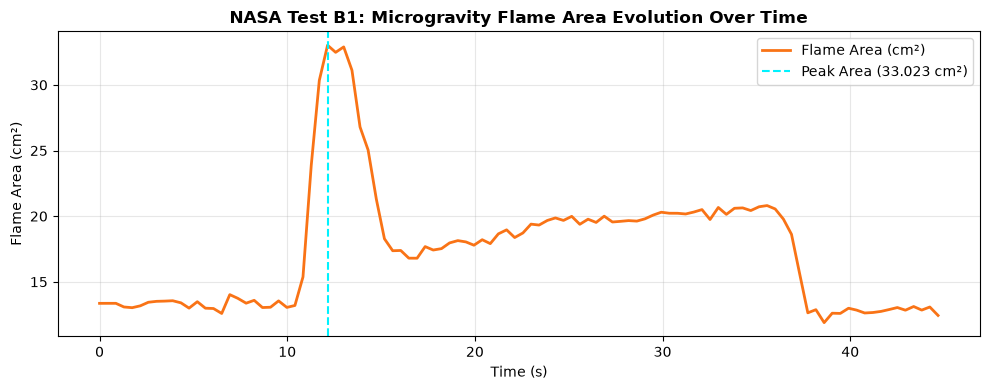

In [7]:
from flame_cv import FlameVideoAnalyzer

cache_path = os.path.join(backend_dir, 'data', 'video_cache', 'analysis_B1.json')
with open(cache_path, 'r') as f:
    analysis_b1 = json.load(f)

summary = analysis_b1['summary']
print("Test B1 Video Analysis Summary:")
print(f"- Peak Flame Area: {summary['max_flame_area_cm2']} cm² (at t = {summary['peak_area_timestamp_s']}s)")
print(f"- Average Flame Area: {summary['avg_flame_area_cm2']} cm²")
print(f"- Flame Stability: {summary['flame_stability']}")
print(f"- Extinction Detected: {summary['extinction_detected']}")

# Plot Flame Area Evolution
timeline = pd.DataFrame(analysis_b1['timeline'])
plt.figure(figsize=(10, 4))
plt.plot(timeline['time_s'], timeline['flame_area_cm2'], color='#f97316', lw=2, label='Flame Area (cm²)')
plt.axvline(summary['peak_area_timestamp_s'], color='#00f2fe', linestyle='--', label=f"Peak Area ({summary['max_flame_area_cm2']} cm²)")
plt.title("NASA Test B1: Microgravity Flame Area Evolution Over Time", fontsize=12, fontweight='bold')
plt.xlabel("Time (s)")
plt.ylabel("Flame Area (cm²)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Model 2 & Model 5: Combustion Prediction & Explainability
Predict microgravity combustion behavior under arbitrary spacecraft environmental conditions (fuel thickness, ambient $O_2$, ventilation speed) and examine SHAP-style feature importance and historical NASA flight matches.

In [8]:
from combustion_models import CombustionIntelligenceEngine

engine = CombustionIntelligenceEngine()
engine.load_models()

# Scenario: PMMA Thin Film in 18% Oxygen at low ventilation (1.5 cm/s)
pred = engine.predict_scenario(
    material="PMMA Thin Film",
    thickness_mm=0.2,
    airflow_velocity_cm_s=1.5,
    oxygen_vol_pct=18.0
)

print(f"Predicted Outcome: {pred['prediction']['outcome_label']} (Confidence: {pred['prediction']['confidence']*100:.1f}%)")
print(f"Predicted Burn Duration: {pred['prediction']['predicted_duration_s']} s")
print(f"Predicted Spread Rate: {pred['prediction']['predicted_spread_rate_cm_s']} cm/s")
print(f"Scientific Rationale: {pred['prediction']['scientific_rationale']}")

print("\nTop Influencing Variables:")
for feat in pred['explainability']['top_influencing_variables']:
    print(f"  • {feat['feature']}: {feat['importance']:.3f}")

print("\nClosest Corroborating NASA Flight Experiments:")
for exp in pred['explainability']['closest_nasa_experiments']:
    print(f"  • Test #{exp['test_id']} ({exp['pi']}): {exp['material']} at {exp['actual_airflow']} cm/s, {exp['actual_o2']}% O2 -> {exp['actual_outcome']} ({int(exp['similarity_score']*100)}% Match)")

Predicted Outcome: Radiative Quenching Extinction (Confidence: 53.3%)
Predicted Burn Duration: 172.2 s
Predicted Spread Rate: 0.078 cm/s
Scientific Rationale: At 18.0% O2 and 1.5 cm/s flow, radiative heat loss from soot and CO2 exceeds chemical heat release. In the absence of natural buoyant convection, the flame cools below its flammability limit.

Top Influencing Variables:
  • Calibrated Initial O2 Vol Pct: 0.410
  • Airflow Velocity Cm S: 0.134
  • Thickness Mm: 0.102
  • Flow Restrictor: 0.090
  • Width Cm: 0.087

Closest Corroborating NASA Flight Experiments:
  • Test #B16 (Bhattacharjee): 2 cm 100 micron thick PMMA at 3.0 cm/s, 17.3% O2 -> extinguished_quenched (92% Match)
  • Test #B17 (Bhattacharjee): 1 cm wide 200 micron thick PMMA at 5.0 cm/s, 17.5% O2 -> extinguished_quenched (91% Match)
  • Test #B20 (Bhattacharjee): 2 cm 100 micron thick PMMA at 5.0 cm/s, 17.4% O2 -> extinguished_quenched (90% Match)


## 4. Model 4: Astronaut Safety Telemetry Anomaly Diagnostics
Distinguish normal atmospheric fluctuations from active fire signatures based on multi-sensor telemetry ($O_2$, $CO$, Airflow, Radiometer).

In [9]:
from rag_engine import AstronautAssistantRAG

assistant = AstronautAssistantRAG()

# Simulated telemetry: O2 drops to 18.2%, CO surges to 65 ppm
diag = assistant.analyze_sensor_telemetry(
    current_o2_pct=18.2,
    current_co_ppm=65.0,
    airflow_cm_s=5.0,
    radiometer_mv=45.0
)

print(f"Hazard Severity: {diag['hazard_severity']}")
print(f"Fire Event Probability: {diag['fire_event_probability']*100:.0f}%")
print("Detected Anomalies:")
for d in diag['detected_deviations']:
    print(f"  - {d}")
print("Recommended Safety Protocols:")
for a in diag['action_recommendations']:
    print(f"  1. {a}")

Hazard Severity: WARNING
Fire Event Probability: 85%
Detected Anomalies:
  - WARNING: CO elevation to 65.0 ppm exceeds safety threshold (50 ppm).
Recommended Safety Protocols:
  1. Verify visual / thermal sensors in active experiments.
  1. Inspect MSG glovebox seals and duct ventilation.


## 5. Launch the FIREWISE-X Full-Stack Platform
The complete web platform is accessible via FastAPI on port 8000.
To start the server from terminal:
```bash
python backend/server.py
```
Then navigate to `http://127.0.0.1:8000/` in your browser to explore:
- **Module 1: Mission Control Dashboard**
- **Module 2: Flame Analysis Studio** (Video playback & AI overlay)
- **Module 3: Pre-Mission Combustion Assessment** (Scenario A vs B vs C)
- **Module 4: Astronaut AI Assistant** (Domain RAG & Telemetry Console)
- **Module 5: Research Intelligence & Reports** (9-Part PDF Generator)